In [12]:
import os, sys
REPO = "https://github.com/salsyaniditiani-commits/simuteh--2330511061-.git"

if not os.path.exists("/content/simuteh"):
    !git clone {REPO} /content/simuteh
os.chdir("/content/simuteh")

for f in ["notebook", "hasil", "laporan"]:
    os.makedirs(f, exist_ok=True)

if not os.path.exists("data/sintetis/citra"):
    !python src/buat_dataset_sintetis.py

os.chdir("/content/simuteh/notebook")
sys.path.append("../src")

print("Folder kerja:", os.getcwd())
print("Jumlah citra:", len(os.listdir("../data/sintetis/citra")))
print("Isi src:", os.listdir("../src"))

Folder kerja: /content/simuteh/notebook
Jumlah citra: 60
Isi src: ['utils_tepi.py', 'bercak.py', 'utils_cv.py', 'praproses.py', '__pycache__', 'buat_dataset_sintetis.py']


**KODE 1.1**

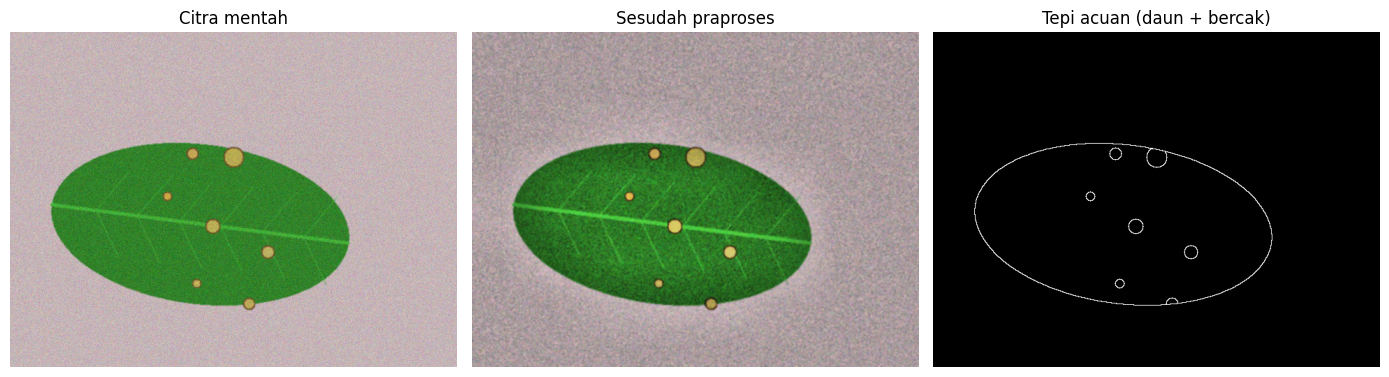

In [13]:
import sys, json
sys.path.append("../src")
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from utils_cv import baca, tampil
from praproses import praproses
from utils_tepi import tepi_acuan, skor_tepi, iou, mask_daun_awal, bercak_awal

pd.set_option("display.width", 160); pd.set_option("display.max_columns", 20)

PARAM = json.load(open("../hasil/param_praproses.json"))   # hasil Evaluasi P1-P4
label = pd.read_csv("../data/sintetis/label.csv")

def muat(nama):
    img = baca(f"../data/sintetis/citra/{nama}")
    md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
    mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
    return img, md, mb

img, md, mb = muat("teh_041.png")
pra = praproses(img, PARAM)
acuan = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
tampil([img, pra, acuan], ["Citra mentah", "Sesudah praproses", "Tepi acuan (daun + bercak)"])

**KODE 1.3**

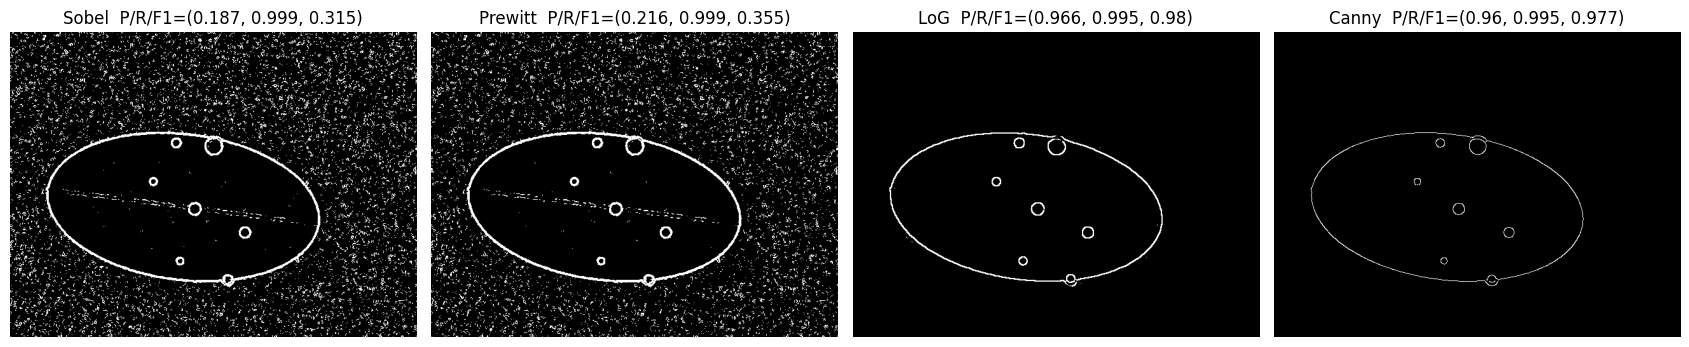

In [14]:
def tepi_sobel(g, T=100):
    g = g.astype(np.float32)
    m = np.hypot(cv2.Sobel(g, cv2.CV_32F, 1, 0), cv2.Sobel(g, cv2.CV_32F, 0, 1))
    return ((m > T) * 255).astype(np.uint8)

def tepi_prewitt(g, T=75):
    kx = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], np.float32)
    g = g.astype(np.float32)
    m = np.hypot(cv2.filter2D(g, -1, kx), cv2.filter2D(g, -1, kx.T))
    return ((m > T) * 255).astype(np.uint8)

def tepi_log(g, sigma=3.0, frac=0.2):
    """Laplacian of Gaussian: tepi = perlintasan nol yang cukup kuat."""
    L = cv2.Laplacian(cv2.GaussianBlur(g.astype(np.float32), (0, 0), sigma),
cv2.CV_32F)
    mn, mx = cv2.erode(L, np.ones((3, 3))), cv2.dilate(L, np.ones((3, 3)))
    return (((mn < 0) & (mx > 0) & (mx - mn > frac * np.abs(L).max())) *
255).astype(np.uint8)

def tepi_canny(g, lo=30, hi=90, sigma=2.0):
    if sigma > 0:
        g = cv2.GaussianBlur(g, (0, 0), sigma)
    return cv2.Canny(g, lo, hi)

metode = {"Sobel": tepi_sobel, "Prewitt": tepi_prewitt, "LoG": tepi_log,
"Canny": tepi_canny}
g = pra[:, :, 2]
hasil = {nm: f(g) for nm, f in metode.items()}
tampil(list(hasil.values()), [f"{nm}  P/R/F1={skor_tepi(e, acuan)}" for nm, e
in hasil.items()],
       ukuran=(17, 3.6))

**KODE 3.1**

         citra  IoU daun awal  komponen bercak awal  komponen acuan IoU bercak awal
0  teh_041.png          0.996                   219               7           0.493
1  teh_021.png          0.998                   236               1            0.04
2  teh_011.png          0.997                   124               0               -


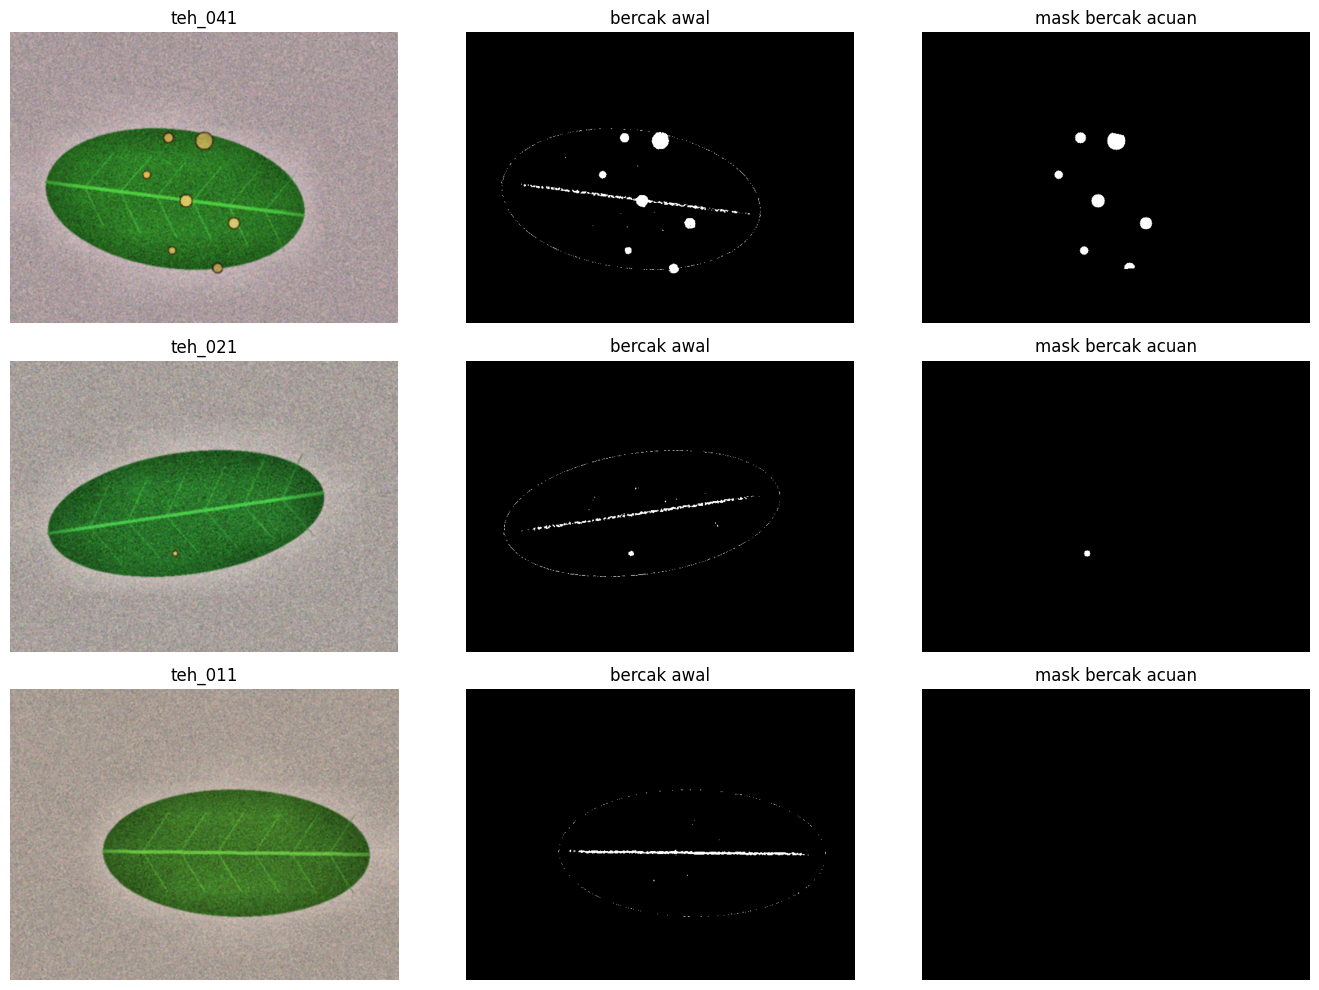

In [15]:
# Menghitung jumlah komponen terhubung
def jumlah_komponen(m, konek=8):
    return cv2.connectedComponents(
        (m > 0).astype(np.uint8),
        connectivity=konek
    )[0] - 1


baris, panel, judul = [], [], []

for nama in ["teh_041.png", "teh_021.png", "teh_011.png"]:  # berat, ringan, sehat
    img, md, mb = muat(nama)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    b0 = bercak_awal(pra_, m_daun, kanal=2, k=4.0)

    baris.append([
        nama,
        round(iou(m_daun, md), 3),
        jumlah_komponen(b0),
        jumlah_komponen(mb),
        round(iou(b0, mb), 3) if mb.any() else "-"
    ])

    panel += [pra_, b0, mb]
    judul += [nama[:7], "bercak awal", "mask bercak acuan"]


print(pd.DataFrame(
    baris,
    columns=[
        "citra",
        "IoU daun awal",
        "komponen bercak awal",
        "komponen acuan",
        "IoU bercak awal"
    ]
))

tampil(panel, judul, baris=3, ukuran=(14, 10))


**KODE 3.2**

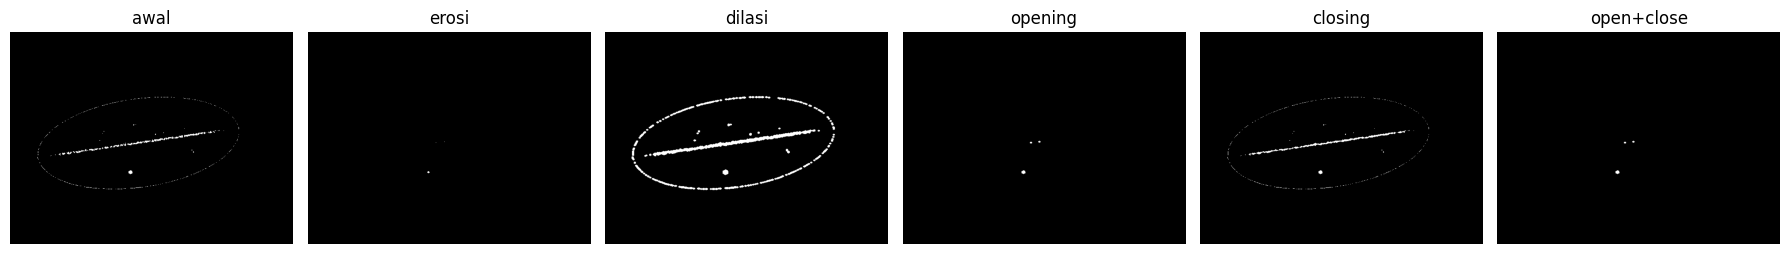

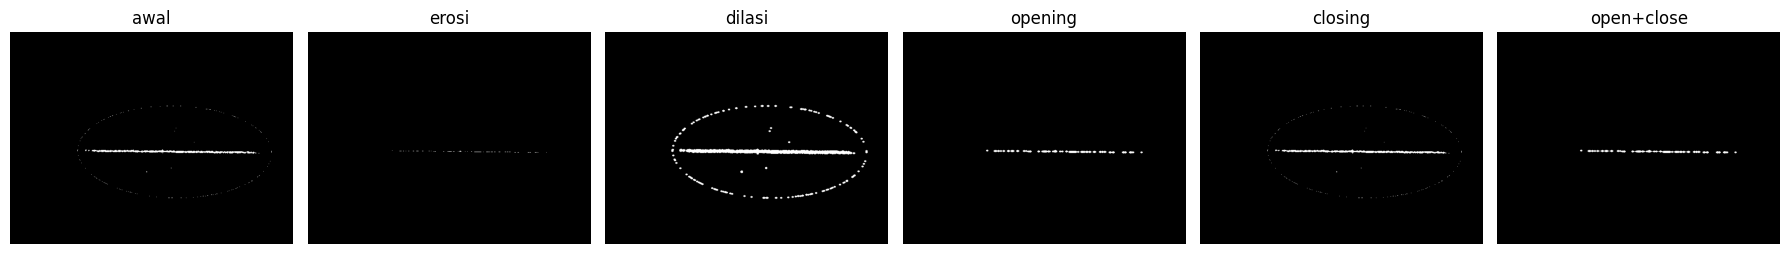

          citra     operasi  komponen  piksel    IoU
0   teh_021.png        awal       236    1472   0.04
1   teh_021.png       erosi         3      19  0.205
2   teh_021.png      dilasi        55    6851  0.012
3   teh_021.png     opening         3      92  0.504
4   teh_021.png     closing       215    1679  0.035
5   teh_021.png  open+close         3      92  0.504
6   teh_011.png        awal       124    1684      -
7   teh_011.png       erosi        41     119      -
8   teh_011.png      dilasi        69    5223      -
9   teh_011.png     opening        20     972      -
10  teh_011.png     closing       122    1716      -
11  teh_011.png  open+close         9    1004      -


In [16]:
SE = lambda k, bentuk=cv2.MORPH_ELLIPSE: cv2.getStructuringElement(bentuk, (k,
k))

def operasi(b, se):
    return {"awal": b,
            "erosi": cv2.erode(b, se),
            "dilasi": cv2.dilate(b, se),
            "opening": cv2.morphologyEx(b, cv2.MORPH_OPEN, se),
            "closing": cv2.morphologyEx(b, cv2.MORPH_CLOSE, se),
            "open+close": cv2.morphologyEx(cv2.morphologyEx(b, cv2.MORPH_OPEN,
se), cv2.MORPH_CLOSE, se)}

baris = []
for nama in ["teh_021.png", "teh_011.png"]:
    img, md, mb = muat(nama)
    pra_ = praproses(img, PARAM)
    b0 = bercak_awal(pra_, mask_daun_awal(pra_))
    hasil = operasi(b0, SE(5))
    for nm, m in hasil.items():
        baris.append([nama, nm, jumlah_komponen(m), int((m > 0).sum()),
                      round(iou(m, mb), 3) if mb.any() else "-"])
    tampil(list(hasil.values()), list(hasil.keys()), ukuran=(18, 3));
plt.show()
print(pd.DataFrame(baris, columns=["citra", "operasi", "komponen", "piksel",
"IoU"]))

**KODE 3.3**

In [17]:
bentuk = {"persegi": cv2.MORPH_RECT, "elips": cv2.MORPH_ELLIPSE, "silang":
cv2.MORPH_CROSS}
baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    n_acuan = jumlah_komponen(mb)
    for k in [3, 4, 6]:
        b0 = bercak_awal(pra_, m_daun, k=k)
        for nb, kb in bentuk.items():
            for uk in [3, 5, 7]:
                se = SE(uk, kb)
                m = cv2.morphologyEx(cv2.morphologyEx(b0, cv2.MORPH_OPEN, se),
cv2.MORPH_CLOSE, se)
                baris.append([d.kelas, k, nb, uk, abs(jumlah_komponen(m) -
n_acuan),
                              iou(m, mb) if mb.any() else np.nan])
eks = pd.DataFrame(baris, columns=["kelas", "k", "bentuk", "ukuran",
"galat_jumlah", "IoU"])
print(eks.pivot_table(index=["k", "bentuk", "ukuran"], columns="kelas",
                      values=["galat_jumlah", "IoU"]).round(2))
eks.to_csv("../hasil/p6_eksperimen_se.csv", index=False)

                   IoU        galat_jumlah              
kelas            berat ringan        berat ringan  sehat
k bentuk  ukuran                                        
3 elips   3       0.57   0.16        20.30  20.90  19.70
          5       0.61   0.23         3.40   4.55   3.45
          7       0.69   0.40         1.45   2.20   1.70
  persegi 3       0.58   0.18         7.30   8.55   7.80
          5       0.64   0.32         2.25   3.40   2.95
          7       0.69   0.42         0.45   0.75   0.15
  silang  3       0.57   0.16        20.30  20.90  19.70
          5       0.62   0.23         6.55   7.55   5.75
          7       0.70   0.37         2.95   4.35   3.35
4 elips   3       0.63   0.28        15.35  14.50  11.60
          5       0.66   0.38         2.20   2.75   2.50
          7       0.69   0.48         0.90   0.65   0.45
  persegi 3       0.64   0.31         5.25   6.10   5.70
          5       0.67   0.45         1.10   1.35   1.05
          7       0.66   0.40  

**Panel SE**

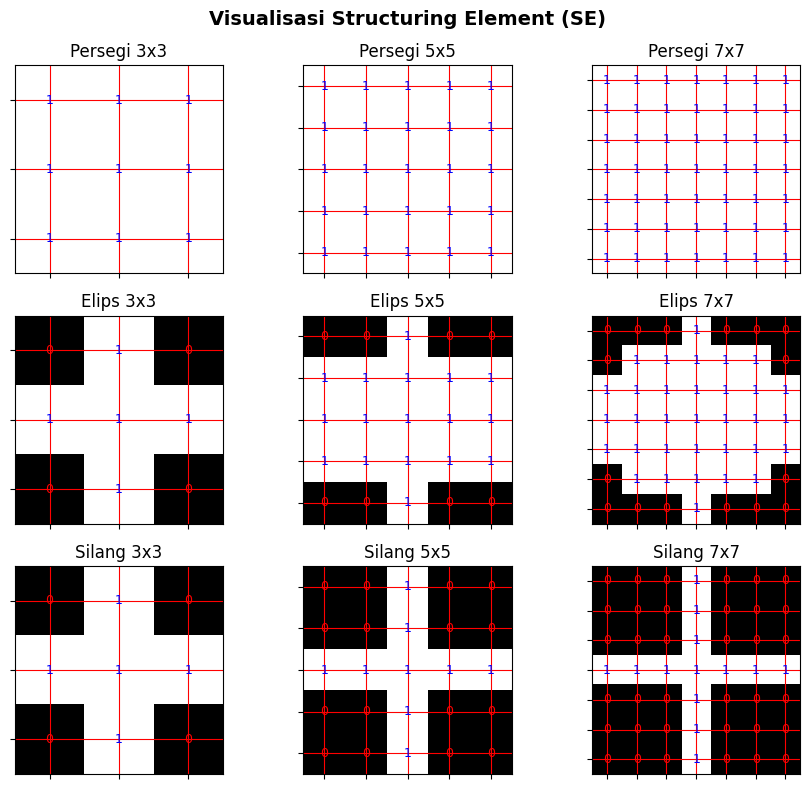

In [18]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Jenis bentuk SE
bentuk_se = {
    "Persegi": cv2.MORPH_RECT,
    "Elips": cv2.MORPH_ELLIPSE,
    "Silang": cv2.MORPH_CROSS
}

ukuran_se = [3, 5, 7]

# Membuat panel 3 x 3
fig, axes = plt.subplots(3, 3, figsize=(9, 8))

for i, (nama, bentuk) in enumerate(bentuk_se.items()):
    for j, ukuran in enumerate(ukuran_se):

        # Membuat structuring element
        se = cv2.getStructuringElement(
            bentuk, (ukuran, ukuran)
        )

        # Menampilkan elemen SE
        axes[i, j].imshow(
            se, cmap="gray", vmin=0, vmax=1,
            interpolation="nearest"
        )

        axes[i, j].set_title(f"{nama} {ukuran}x{ukuran}")
        axes[i, j].set_xticks(range(ukuran))
        axes[i, j].set_yticks(range(ukuran))
        axes[i, j].grid(color="red", linewidth=0.8)

        axes[i, j].set_xticklabels([])
        axes[i, j].set_yticklabels([])

        # Memberikan nilai 0 dan 1 pada setiap sel
        for y in range(ukuran):
            for x in range(ukuran):
                axes[i, j].text(
                    x, y, str(se[y, x]),
                    ha="center", va="center",
                    color="red" if se[y, x] == 0 else "blue",
                    fontsize=9
                )

plt.suptitle(
    "Visualisasi Structuring Element (SE)",
    fontsize=14, fontweight="bold"
)

plt.tight_layout()
plt.savefig("../hasil/p6_visualisasi_se.png",
            dpi=300, bbox_inches="tight")
plt.show()


**KODE 3.4**

In [19]:

baris = []

for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)

    grad = cv2.morphologyEx(
        m_daun,
        cv2.MORPH_GRADIENT,
        SE(3)
    )  # dilasi - erosi

    canny = tepi_canny(cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY))
    ad = tepi_acuan(md)

    baris.append([
        d.kondisi_cahaya,
        skor_tepi(grad, ad)[2],
        skor_tepi(canny, ad)[2]
    ])

print(
    pd.DataFrame(
        baris,
        columns=["kondisi", "F1 gradien morfologi", "F1 Canny"]
    )
    .groupby("kondisi")
    .mean()
    .round(3)
)


                F1 gradien morfologi  F1 Canny
kondisi                                       
bayangan                       0.861     0.717
gelap                          0.983     0.690
kontras_rendah                 0.248     0.912
normal                         0.989     0.688
terang                         0.914     0.692


**KODE 4.1**

konektivitas 4: 13 komponen
konektivitas 8: 13 komponen
    label  luas_px  luas_mm2  keliling_px  kebulatan  rasio_aspek   cx   cy
0       1      624    119.44         93.5       0.90         1.04  320  178
1       2      183     35.03         47.8       1.01         1.00  261  173
2       3      113     21.63         37.0       1.04         1.20  224  234
3       4       27      5.17         17.7       1.09         1.50  183  263
4       5       25      4.79         19.3       0.84         1.50  228  269
5       6      344     65.84         77.0       0.73         1.12  290  278
6       7       17      3.25         13.7       1.15         1.25  329  282
7       8       24      4.59         16.5       1.11         1.44  339  283
8       9       30      5.74         18.5       1.10         1.20  378  288
9      10       17      3.25         13.7       1.15         1.25  389  290
10     11      255     48.81         59.5       0.91         1.00  368  315
11     12      102     19.52    

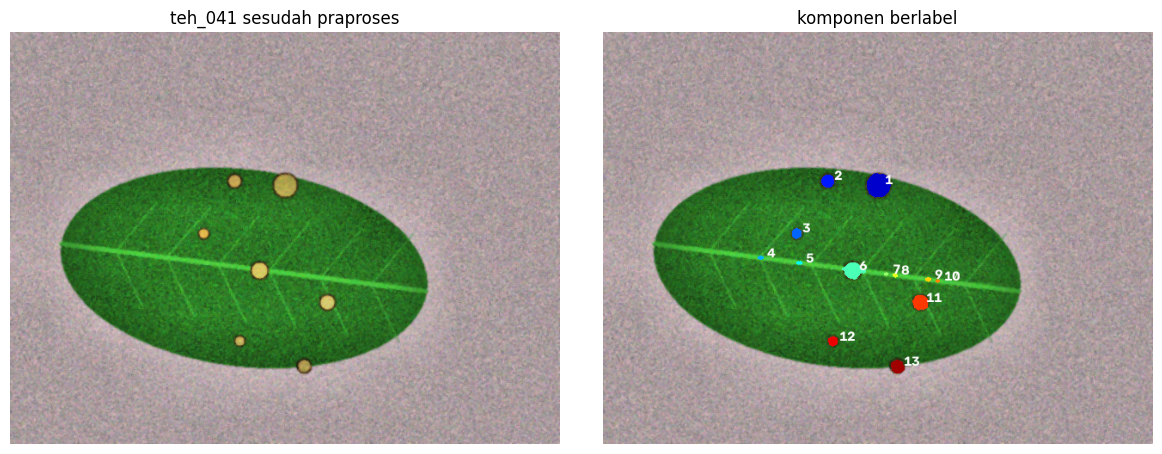

In [20]:

MM_PER_PX = 0.4375  # dari lembar hitung P2: Z = 200 mm, lebar kerja 640 px

def ukur_komponen(m, konek=8):
    n, lbl, st, cen = cv2.connectedComponentsWithStats((m > 0).astype(np.uint8), connectivity=konek)
    baris = []
    for i in range(1, n):
        kontur, _ = cv2.findContours((lbl == i).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        A = int(st[i, cv2.CC_STAT_AREA])
        keliling = cv2.arcLength(kontur[0], True)
        kebulatan = 0.0 if keliling == 0 else 4 * np.pi * A / keliling ** 2
        w, h = cv2.minAreaRect(kontur[0])[1]
        rasio = max(w, h) / max(min(w, h), 1)
        baris.append([i, A, round(A * MM_PER_PX ** 2, 2), round(keliling, 1), round(kebulatan, 2), round(rasio, 2), int(cen[i][0]), int(cen[i][1])])
    kolom = ["label", "luas_px", "luas_mm2", "keliling_px", "kebulatan", "rasio_aspek", "cx", "cy"]
    return pd.DataFrame(baris, columns=kolom), lbl

img, md, mb = muat("teh_041.png")
pra_ = praproses(img, PARAM)
m_daun = mask_daun_awal(pra_)
bersih = cv2.morphologyEx(cv2.morphologyEx(bercak_awal(pra_, m_daun), cv2.MORPH_OPEN, SE(5)), cv2.MORPH_CLOSE, SE(5))

for konek in [4, 8]:
    print(f"konektivitas {konek}: {jumlah_komponen(bersih, konek)} komponen")

tabel_kom, lbl = ukur_komponen(bersih)
print(tabel_kom)

warna = cv2.applyColorMap((lbl * (255 // max(lbl.max(), 1))).astype(np.uint8), cv2.COLORMAP_JET)
warna[lbl == 0] = pra_[lbl == 0]
for _, r in tabel_kom.iterrows():
    cv2.putText(warna, str(int(r.label)), (int(r.cx) + 8, int(r.cy)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 2)

tampil([pra_, warna], ["teh_041 sesudah praproses", "komponen berlabel"], ukuran=(12, 4.5))


**KODE 4.2**

In [21]:
def saring(m, luas_min=20, bulat_min=0.5, rasio_maks=1.8):
    tabel_k, lbl = ukur_komponen(m)
    lolos = tabel_k[(tabel_k.luas_px >= luas_min) & (tabel_k.kebulatan >=
bulat_min)
                    & (tabel_k.rasio_aspek <= rasio_maks)]
    return (np.isin(lbl, lolos.label.values) * 255).astype(np.uint8), lolos

aturan = {"tanpa saring": (0, 0, 99), "luas >= 20": (20, 0, 99),
          "luas + kebulatan": (20, 0.5, 99), "luas + kebulatan + rasio": (20,
0.5, 1.8)}
baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    bersih = cv2.morphologyEx(cv2.morphologyEx(bercak_awal(pra_, m_daun),
cv2.MORPH_OPEN, SE(5)),
                              cv2.MORPH_CLOSE, SE(5))
    for nm, (a, b, r) in aturan.items():
        f, _ = saring(bersih, a, b, r)
        baris.append([d.kelas, nm, jumlah_komponen(f), jumlah_komponen(mb)])
uji = pd.DataFrame(baris, columns=["kelas", "aturan", "jumlah", "acuan"])
uji["galat"] = (uji.jumlah - uji.acuan).abs()
print(uji.pivot_table(index="aturan", columns="kelas",
values="galat").round(2))
print("Daun sehat yang masih memiliki bercak palsu:")
print(uji[uji.kelas == "sehat"].assign(palsu=lambda t: t.jumlah >
0).groupby("aturan").palsu.sum())


kelas                     berat  ringan  sehat
aturan                                        
luas + kebulatan           1.05    1.45   0.65
luas + kebulatan + rasio   0.85    0.75   0.40
luas >= 20                 1.50    1.90   1.40
tanpa saring               2.20    2.75   2.50
Daun sehat yang masih memiliki bercak palsu:
aturan
luas + kebulatan             8
luas + kebulatan + rasio     7
luas >= 20                  10
tanpa saring                12
Name: palsu, dtype: int64


**DIAGRAM SEBAR 4.4**

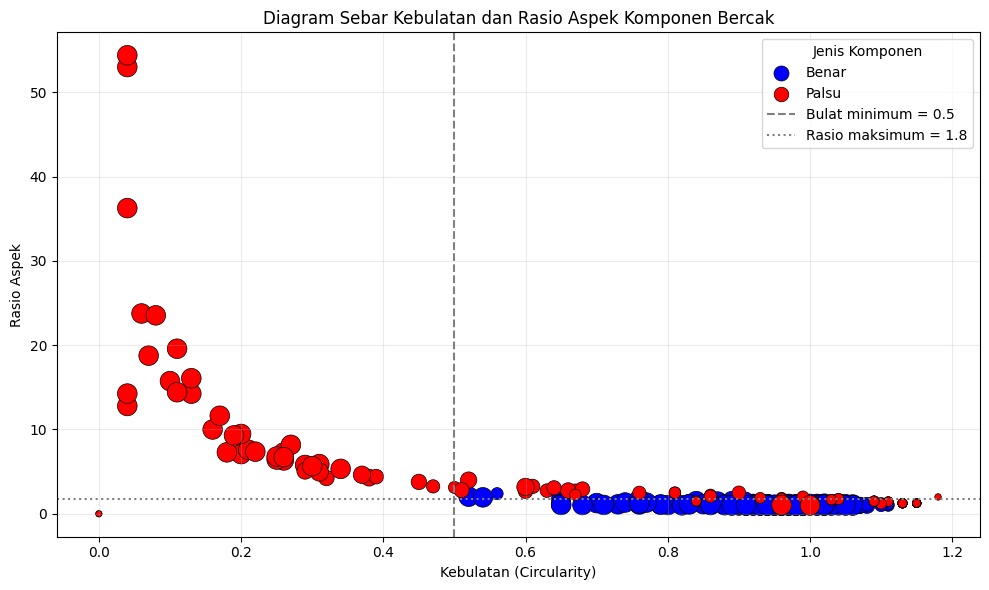

In [24]:

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

data_komponen = []

for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    bersih = cv2.morphologyEx(cv2.morphologyEx(bercak_awal(pra_, m_daun), cv2.MORPH_OPEN, SE(5)),
                              cv2.MORPH_CLOSE, SE(5))

    tabel_k, lbl = ukur_komponen(bersih)

    for _, r in tabel_k.iterrows():
        komponen = lbl == int(r.label)
        proporsi = np.sum(komponen & (mb > 0)) / np.sum(komponen)
        status = "Benar" if proporsi > 0.5 else "Palsu"

        data_komponen.append([d.nama_file, d.kelas, r.luas_px,
                              r.kebulatan, r.rasio_aspek, proporsi, status])

df_komponen = pd.DataFrame(data_komponen, columns=[
    "citra", "kelas", "luas_px", "kebulatan",
    "rasio_aspek", "proporsi_acuan", "status"
])
# Diagram sebar
plt.figure(figsize=(10, 6))
warna = {"Benar": "#0000FF", "Palsu": "#FF0000"}

for status in ["Benar", "Palsu"]:
    d = df_komponen[df_komponen.status == status]
    plt.scatter(d.kebulatan, d.rasio_aspek,
                s=np.clip(d.luas_px * 2, 20, 200),
                c=warna[status], label=status,
                alpha=1, edgecolors="black", linewidths=0.5)

plt.axvline(0.5, color="gray", linestyle="--",
            label="Bulat minimum = 0.5")
plt.axhline(1.8, color="gray", linestyle=":",
            label="Rasio maksimum = 1.8")

plt.title("Diagram Sebar Kebulatan dan Rasio Aspek Komponen Bercak")
plt.xlabel("Kebulatan (Circularity)")
plt.ylabel("Rasio Aspek")
plt.legend(title="Jenis Komponen")
plt.grid(alpha=0.25)
plt.tight_layout()

# Simpan diagram
plt.savefig("P6_Diagram_Sebar.png", dpi=300, bbox_inches="tight")

plt.show()